# 🔍 Fake News Detection System
### End-Semester NLP Project
**Owner: Member 5** · Model: Multinomial Naive Bayes · Vectorizer: TF-IDF

---
### Notebook Workflow
```
Fake.csv + True.csv
    ↓  label (0=FAKE, 1=REAL)
    ↓  clean_text()
    ↓  TfidfVectorizer  (max 5000 features)
    ↓  train_test_split (80% train / 20% test)
    ↓  MultinomialNB.fit()
    ↓  Evaluate: accuracy, confusion matrix, precision, recall, F1
    ↓  Save model.pkl + vectorizer.pkl
```

In [1]:
# ── Imports ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, pickle, math

print('✅ All libraries imported successfully')

✅ All libraries imported successfully


## Step 1 — Load & Label Dataset

In [4]:
fake = pd.read_csv('Fake.csv')
true = pd.read_csv('True.csv')

print(f'Fake articles : {len(fake):,}')
print(f'True articles : {len(true):,}')

fake['label'] = 0   # 0 = FAKE
true['label'] = 1   # 1 = REAL

data = pd.concat([fake, true])[['text', 'label']].dropna()
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\nCombined dataset: {len(data):,} articles')
print(data['label'].value_counts().rename({0:'FAKE', 1:'REAL'}))
data.head()

Fake articles : 23,481
True articles : 21,417

Combined dataset: 44,898 articles
label
FAKE    23481
REAL    21417
Name: count, dtype: int64


,text,label
0,"21st Century Wire says Ben Stein, reputable pr...",0
1,WASHINGTON (Reuters) - U.S. President Donald T...,1
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,1
3,"On Monday, Donald Trump once again embarrassed...",0
4,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",1


## Step 2 — Text Preprocessing
| Step | Operation |
|---|---|
| 1 | Lowercase |
| 2 | Remove URLs (`http://...`) |
| 3 | Keep letters only |
| 4 | Collapse whitespace |

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)      # remove URLs
    text = re.sub(r'[^a-zA-Z ]', '', text)   # letters only
    text = re.sub(r'\s+', ' ', text).strip() # normalise spaces
    return text

data['text'] = data['text'].apply(clean_text)
print('✅ Text cleaned')
print('\nSample (first 200 chars):')
print(data['text'].iloc[0][:200])

✅ Text cleaned

Sample (first 200 chars):
st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appearing in tv shows and films such as ferris bueller s day off made some provocative stateme


## Step 3 — Manual TF Calculation (for understanding)
**Formula:** `TF(t, d) = count(t, d) / total_words(d)`

In [6]:
def compute_tf_for_doc(doc):
    words = doc.split()
    total = len(words)
    wc    = {}
    for w in words:
        wc[w] = wc.get(w, 0) + 1
    return {w: c/total for w, c in wc.items()}

sample_tf = compute_tf_for_doc(data['text'].iloc[0])
top5_tf   = sorted(sample_tf.items(), key=lambda x: x[1], reverse=True)[:5]

print('Top-5 TF values in first document:')
print(f'{"Word":<20} {"TF"}')
print('-' * 32)
for w, v in top5_tf:
    print(f'{w:<20} {v:.6f}')

Top-5 TF values in first document:
Word                 TF
--------------------------------
the                  0.100000
in                   0.029412
and                  0.029412
of                   0.023529
on                   0.023529


## Step 4 — TF-IDF Vectorization (sklearn)
**Formulas:**
```
IDF(t)       = log((N+1) / (df(t)+1)) + 1     ← smooth IDF
TF-IDF(t,d)  = TF(t,d) × IDF(t)
```

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(data['text'])
y = data['label']

print(f'TF-IDF matrix shape: {X.shape}')
print(f'  Rows    = {X.shape[0]:,}  (documents)')
print(f'  Columns = {X.shape[1]:,}  (features / vocabulary size)')

TF-IDF matrix shape: (44898, 5000)
  Rows    = 44,898  (documents)
  Columns = 5,000  (features / vocabulary size)


## Step 5 — Train / Test Split
80% for training, 20% held out for evaluation.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Training samples : {X_train.shape[0]:,}')
print(f'Testing  samples : {X_test.shape[0]:,}')

Training samples : 35,918
Testing  samples : 8,980


## Step 6 — Train Multinomial Naive Bayes
```
Bayes Theorem   : P(C|d) = P(C) × P(d|C) / P(d)
Naive Bayes     : P(C|d) ∝ P(C) × ∏ P(wᵢ|C)
Log-Likelihood  : log P(C|d) = log P(C) + Σ log P(wᵢ|C)
```
MultinomialNB is ideal for text data with TF-IDF features (non-negative values).

In [9]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)

print('✅ Model trained!')
print(f'Classes          : {model.classes_}  (0=FAKE, 1=REAL)')
print(f'Log Prior FAKE   : {model.class_log_prior_[0]:.4f}')
print(f'Log Prior REAL   : {model.class_log_prior_[1]:.4f}')

✅ Model trained!
Classes          : [0 1]  (0=FAKE, 1=REAL)
Log Prior FAKE   : -0.6489
Log Prior REAL   : -0.7394


## Step 7 — Evaluate Model

In [10]:
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    precision_score, recall_score, f1_score,
    classification_report
)

y_pred = model.predict(X_test)

acc       = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
cm        = confusion_matrix(y_test, y_pred)

print('═' * 46)
print('  MULTINOMIAL NAIVE BAYES — RESULTS')
print('═' * 46)
print(f'  Accuracy  : {acc*100:.2f}%')
print(f'  Precision : {precision*100:.2f}%')
print(f'  Recall    : {recall*100:.2f}%')
print(f'  F1 Score  : {f1*100:.2f}%')
print('═' * 46)
print()
print(classification_report(y_test, y_pred, target_names=['FAKE','REAL']))

══════════════════════════════════════════════
  MULTINOMIAL NAIVE BAYES — RESULTS
══════════════════════════════════════════════
  Accuracy  : 93.82%
  Precision : 93.01%
  Recall    : 94.07%
  F1 Score  : 93.54%
══════════════════════════════════════════════

              precision    recall  f1-score   support

        FAKE       0.95      0.94      0.94      4710
        REAL       0.93      0.94      0.94      4270

    accuracy                           0.94      8980
   macro avg       0.94      0.94      0.94      8980
weighted avg       0.94      0.94      0.94      8980



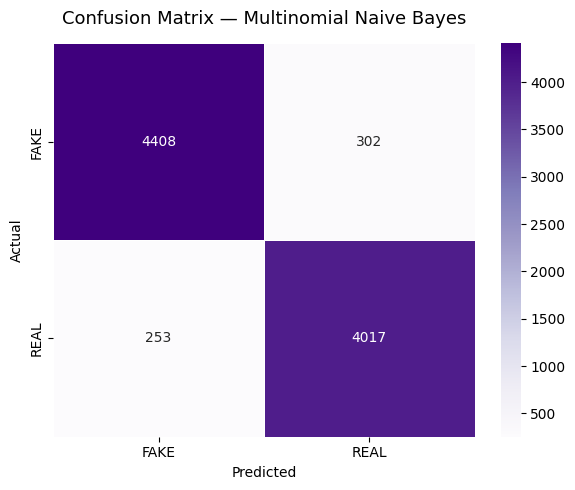

TN=4408  FP=302  FN=253  TP=4017


In [11]:
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Purples',
    xticklabels=['FAKE','REAL'],
    yticklabels=['FAKE','REAL'],
    linewidths=0.5, ax=ax
)
ax.set_title('Confusion Matrix — Multinomial Naive Bayes', pad=14, fontsize=13)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

## Step 8 — Demo Prediction with Full Walkthrough

In [ ]:
sample = "SHOCKING: Scientists discover miracle cure that doctors don't want you to know!"

cleaned = clean_text(sample)
vec     = vectorizer.transform([cleaned])
pred    = model.predict(vec)[0]
proba   = model.predict_proba(vec)[0]
log_p   = model.predict_log_proba(vec)[0]

label = 'FAKE 🔴' if pred == 0 else 'REAL 🟢'
conf  = proba[0]*100 if pred == 0 else proba[1]*100

print(f'Input     : {sample}')
print(f'Cleaned   : {cleaned}')
print()
print(f'Prediction  : {label}')
print(f'Confidence  : {conf:.2f}%')
print(f'P(FAKE|doc) : {proba[0]*100:.2f}%')
print(f'P(REAL|doc) : {proba[1]*100:.2f}%')
print(f'log P(FAKE) : {log_p[0]:.4f}')
print(f'log P(REAL) : {log_p[1]:.4f}')

# TF-IDF breakdown
words  = cleaned.split()
total  = len(words)
vocab  = vectorizer.vocabulary_
idf_v  = vectorizer.idf_

scores = {}
for w in set(words):
    if w in vocab:
        cnt   = words.count(w)
        tf    = cnt / total
        idf   = idf_v[vocab[w]]
        tfidf = tf * idf
        scores[w] = (cnt, tf, idf, tfidf)

top = sorted(scores.items(), key=lambda x: x[1][3], reverse=True)[:5]
print()
print(f'{"Word":<18} {"Count":<7} {"TF":<12} {"IDF":<9} {"TF-IDF"}')
print('-' * 58)
for w, (cnt, tf, idf, tfidf) in top:
    print(f'{w:<18} {cnt:<7} {tf:<12.6f} {idf:<9.4f} {tfidf:.6f}')

## Step 9 — Save model.pkl and vectorizer.pkl

In [ ]:
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)

with open('vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

print('✅ model.pkl      saved')
print('✅ vectorizer.pkl saved')
print()
print('To load elsewhere:')
print("  import pickle")
print("  model      = pickle.load(open('model.pkl', 'rb'))")
print("  vectorizer = pickle.load(open('vectorizer.pkl', 'rb'))")